# 03 — SARIMA: identification des ordresNotebook 02 a fixé la barre: **845 MW de MAE** sur le test (RTE débiaisé par heure, fenêtre 15 jours).Ce notebook ne cherche pas encore à battre cette barre. Il répond à une question plus modeste,celle des TP02/TP03: **la série de consommation, vue seule, contient-elle assez de structureautorégressive pour qu'un SARIMA ait un sens ?** On regarde la stationnarité, on choisit lesdifférenciations, et on lit les ordres candidats dans l'ACF et la PACF.Toute cette identification se fait **sur le train uniquement** (2019-2023). La validation 2024servira à départager les ordres candidats, le test 2025-2026 ne sera touché qu'à la fin.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

from time_series_m2.utils.data import load_national
from time_series_m2.utils.splits import mask

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 4)

df = load_national()
train = df.loc[mask(df.index, 'train')]
y = train['load_mw']
print(f'train: {len(y)} heures, {y.index.min()} -> {y.index.max()}')

train: 43823 heures, 2019-01-01 01:00:00+01:00 -> 2023-12-31 23:00:00+01:00


## 1. La série telle qu'elle estTrois saisonnalités s'empilent: journalière (24 h), hebdomadaire (168 h) et annuelle.C'est la difficulté centrale pour un SARIMA, qui ne sait en absorber qu'une seule par sonterme saisonnier.

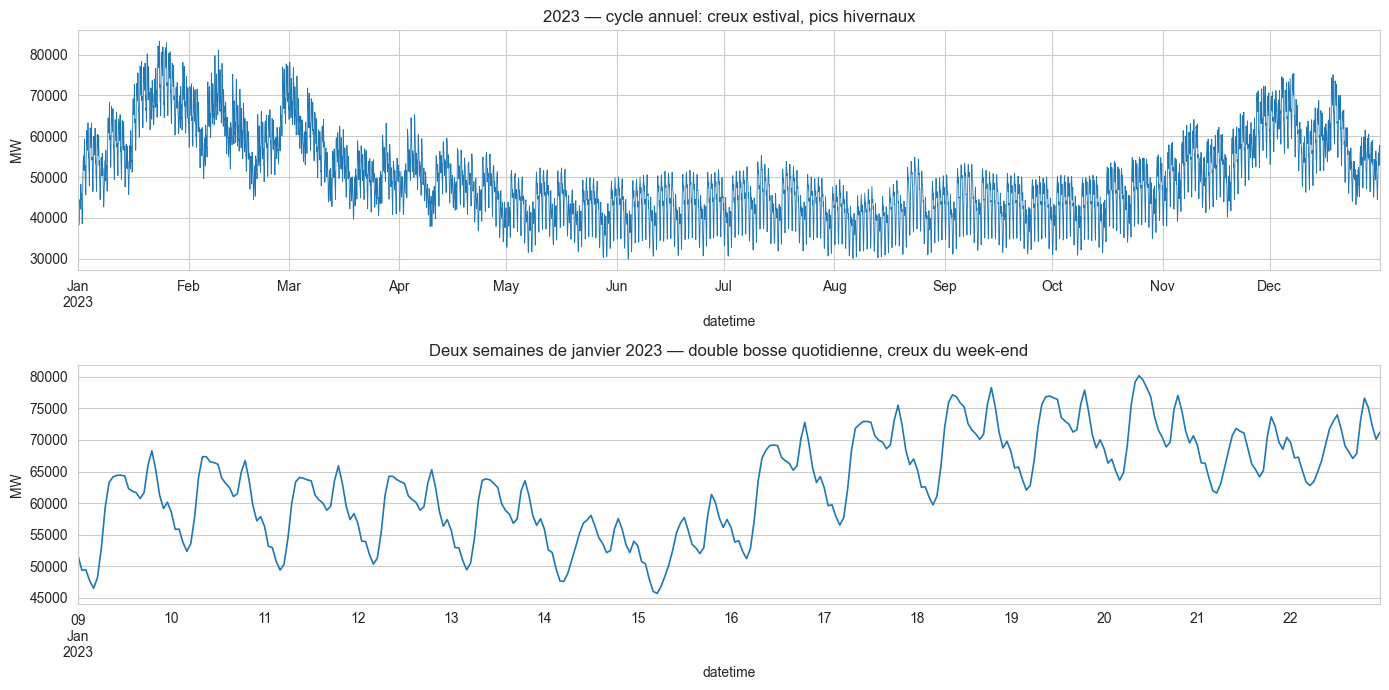

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

y.loc['2023'].plot(ax=axes[0], lw=0.6)
axes[0].set(title='2023 — cycle annuel: creux estival, pics hivernaux', ylabel='MW')

y.loc['2023-01-09':'2023-01-22'].plot(ax=axes[1], lw=1.2)
axes[1].set(title='Deux semaines de janvier 2023 — double bosse quotidienne, creux du week-end',
            ylabel='MW')
plt.tight_layout()

## 2. Stationnarité et choix des différenciationsDeux tests, volontairement complémentaires car leurs hypothèses nulles sont opposées:- **ADF** — H0: racine unitaire (non stationnaire). On veut **rejeter**, donc p petit.- **KPSS** — H0: stationnarité. On veut **ne pas rejeter**, donc p grand.Les deux doivent être d'accord. On les applique aux candidats de différenciation, et onregarde aussi l'écart-type résiduel: une différenciation utile réduit nettement la variance,une différenciation de trop la fait remonter.

In [3]:
def stationarity(series, label, n_tail=20000):
    """ADF et KPSS sur la queue de la série (les tests sont coûteux en O(n))."""
    s = series.dropna()
    sub = s.iloc[-n_tail:]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')  # p-values saturées aux bornes de la table
        adf = adfuller(sub, autolag='AIC')
        kps = kpss(sub, regression='c', nlags='auto')
    return {'transformation': label, 'ADF stat': adf[0], 'ADF p': adf[1],
            'KPSS stat': kps[0], 'KPSS p': kps[1], 'ecart-type': s.std()}


candidates = {
    'brute':            y,
    'd=1':              y.diff(1),
    'D=1 (s=24)':       y.diff(24),
    'd=1, D=1 (s=24)':  y.diff(24).diff(1),
    'D=1 (s=168)':      y.diff(168),
    'D=1 (s=24) + (s=168)': y.diff(24).diff(168),
}
table = pd.DataFrame([stationarity(s, k) for k, s in candidates.items()]).set_index('transformation')
table.round(3)

,ADF stat,ADF p,KPSS stat,KPSS p,ecart-type
transformation,,,,,
brute,-5.410,0.0,3.138,0.01,11308.173
d=1,-21.985,0.0,0.041,0.10,2137.718
D=1 (s=24),-23.223,0.0,0.022,0.10,4029.770
"d=1, D=1 (s=24)",-33.834,0.0,0.001,0.10,804.584
D=1 (s=168),-8.671,0.0,0.089,0.10,5075.783
D=1 (s=24) + (s=168),-17.456,0.0,0.004,0.10,2858.561


**Lecture.**Sur la série brute, les deux tests se contredisent: l'ADF rejette la racine unitaire, le KPSSrejette la stationnarité. Ce n'est pas une anomalie — c'est la signature d'une série**fortement saisonnière mais sans tendance stochastique**. L'ADF voit un retour à la moyenne(la conso revient toujours autour de 55 GW), le KPSS voit une moyenne locale qui bouge sansarrêt (nuit vs jour, été vs hiver). Il faut différencier, pas parce qu'il y a une tendance,mais pour retirer la saisonnalité.À partir de `D=1 (s=24)` les deux tests sont d'accord. Le choix se joue alors sur l'écart-type:| transformation | écart-type ||---|---|| brute | 11 308 MW || D=1 (s=24) | 4 030 MW || d=1, D=1 (s=24) | **805 MW** || D=1 (s=168) | 5 076 MW |La différenciation saisonnière à 24 h divise la variance par 2,8. Ajouter la différenciationsimple la divise encore par 5. On retient **d=1, D=1, s=24**.Deux remarques honnêtes:- `s=168` différencie bien, mais un SARIMA de période 168 est hors de portée en temps de  calcul (la matrice d'état a une dimension de l'ordre de la période). On ne le retient pas.- Un écart-type plus petit n'est pas en soi une preuve: sur-différencier réduit aussi la  variance tout en introduisant de la corrélation négative artificielle. C'est l'ACF ci-dessous  qui tranche, et elle ne montre pas de MA(1) parasite à −0,5.

## 3. ACF et PACF — lire les ordresOn regarde deux séries: la série seulement saisonnièrement différenciée (`D=1`), puis celledoublement différenciée (`d=1, D=1`), celle qu'on modélisera.

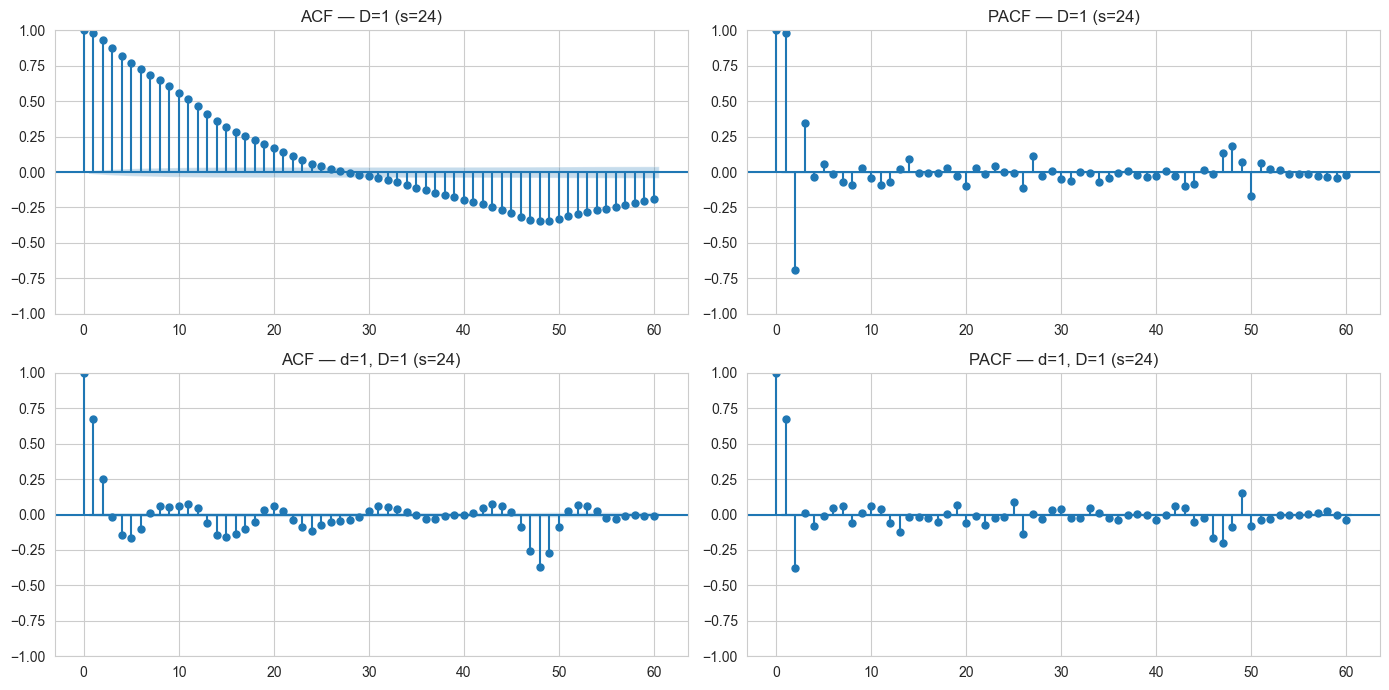

In [4]:
d24 = y.diff(24).dropna()
d24_d1 = y.diff(24).diff(1).dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(d24, lags=60, ax=axes[0, 0], title='ACF — D=1 (s=24)')
plot_pacf(d24, lags=60, ax=axes[0, 1], method='ywm', title='PACF — D=1 (s=24)')
plot_acf(d24_d1, lags=60, ax=axes[1, 0], title='ACF — d=1, D=1 (s=24)')
plot_pacf(d24_d1, lags=60, ax=axes[1, 1], method='ywm', title='PACF — d=1, D=1 (s=24)')
plt.tight_layout()

In [5]:
lags = [1, 2, 3, 4, 23, 24, 25, 48, 72, 168]
a = acf(d24_d1, nlags=max(lags))
p = pacf(d24_d1, nlags=50, method='ywm')

readout = pd.DataFrame(
    {'ACF': [a[k] for k in lags],
     'PACF': [p[k] if k < len(p) else np.nan for k in lags]},
    index=pd.Index(lags, name='lag'),
)
print(f'seuil de significativite ~ +/- {1.96 / np.sqrt(len(d24_d1)):.4f}')
readout.round(3)

seuil de significativite ~ +/- 0.0094


,ACF,PACF
lag,,
1,0.676,0.676
2,0.250,-0.381
3,-0.018,0.012
4,-0.145,-0.082
23,-0.090,-0.025
24,-0.117,-0.019
25,-0.074,0.086
48,-0.369,-0.086
72,0.016,NaN


**Lecture des ordres, partie non saisonnière.**Sur `d=1, D=1`: l'ACF décroît (0,68 → 0,25 → −0,02 → −0,15) et la PACF coupe net après lelag 2 (0,68 ; −0,38 ; 0,01). Signature d'un **AR(2)**, donc `p = 2`, `q = 0`.**Partie saisonnière.** Ici le manuel ne s'applique pas proprement, et il faut le dire. Onattendrait une ACF saisonnière qui coupe après le lag 24. Elle ne le fait pas: −0,117 au lag24, mais −0,369 au lag 48 et −0,360 au lag 120. Ces lags ne décroissent pas, ils **oscillent**.La raison apparaît en section 4: le cycle hebdomadaire survit à la différenciation et imposesa propre oscillation de période 168 sur toute la grille des lags multiples de 24. L'ACF auxlags saisonniers mesure donc un mélange de deux choses, et elle n'est pas lisible.On retient donc `P = 0`, `Q = 1` **par l'argument théorique et non par le graphe**:différencier à l'ordre 24 introduit mécaniquement un terme MA(1) saisonnier dans le processusdifférencié, qu'il vaut mieux estimer que subir. Ce choix sera tranché empiriquement sur lavalidation 2024, pas ici.Candidat de référence: **SARIMA(2,1,0)(0,1,1)[24]**, à confirmer.

## 4. Le problème que SARIMA ne résoudra pasUn chiffre décide de toute la suite du projet.

In [6]:
long_acf = acf(d24_d1, nlags=336)
weekly = pd.Series({f'lag {k}': long_acf[k] for k in (24, 48, 72, 96, 120, 144, 168, 336)})
weekly.round(3)

lag 24    -0.117
lag 48    -0.369
lag 72     0.016
lag 96     0.016
lag 120   -0.360
lag 144   -0.037
lag 168    0.748
lag 336    0.708
dtype: float64

Après avoir différencié deux fois, l'autocorrélation au **lag 168 reste à 0,75** — plus forte que tout ce qui subsiste en dessous de 100. La structure hebdomadaire traverse intacte les différenciations journalières.

C'est logique: `D=1, s=24` retire ce qui se répète d'un jour sur l'autre, donc elle traite un lundi et un samedi comme deux jours interchangeables. Or ils ne le sont pas. Le terme saisonnier de période 24 ne peut structurellement pas capter un cycle de période 168.

Trois issues possibles, une seule praticable:

| option | verdict |
|---|---|
| `s = 168` | infaisable — espace d'état de dimension ~168, des heures de fit par modèle |
| deux termes saisonniers (24 et 168) | pas supporté par `SARIMAX` de statsmodels |
| **jour de semaine en régresseur exogène** | retenu |

On passe donc à **SARIMAX**: la partie SARIMA absorbe le cycle journalier et la dynamique de court terme, des régresseurs exogènes portent ce qu'elle ne peut pas voir — jour de semaine, jours fériés, ponts, degrés-jours de chauffage et de climatisation. C'est la pratique standard sur la consommation électrique, et ça reste dans le cadre du TP03.

**Attendu, dit d'avance.** SARIMAX ne voit que l'historique de la série et quelques régresseurs calendaires. RTE intègre un modèle météo complet et de l'expertise réseau. Il est probable que SARIMAX perde contre les 845 MW. Son rôle ici n'est pas de gagner: c'est d'établir ce qu'on obtient avec un modèle purement statistique, et de montrer **où** il échoue — ce qui justifiera le passage au ML au notebook suivant.

## 5. Le modèle: prévision day-ahead sous la contrainte de l'enchère

`sarima.model.forecast_days` ne fait jamais de prévision à un pas. Pour chaque jour cible D+1:

- l'historique s'arrête au **cutoff** (11:00 le jour D), sur une fenêtre glissante de 60 jours;
- les 24 heures du lendemain sont prévues à des horizons de **13 à 36 h**;
- les paramètres sont ré-estimés **une fois par semaine** (départ à chaud depuis le fit précédent), et le filtre est mis à jour chaque jour avec les mêmes paramètres.

Le test `test_load_after_the_cutoff_cannot_change_the_forecast` pose la charge postérieure au cutoff à 0 MW et vérifie que la prévision ne bouge pas.

## 6. Choix des ordres sur la validation 2024

Cinq candidats, évalués sur **52 jours de 2024** (un jour sur sept, toutes saisons), jamais sur le test. L'ordre `(2,1,0)(0,1,1)[24]` est celui lu dans l'ACF/PACF; les autres testent ce que cette lecture écarte: pas de différenciation régulière, un AR plus long, un ARMA mixte, un AR saisonnier.

Les résultats viennent de `scripts/run_sarima.py grid` (une dizaine de minutes).

In [7]:
grid = pd.read_csv('../results/sarima/grid_val.csv')
grid[['order', 'seasonal_order', 'MAE', 'RMSE', 'MAPE', 'bias']].round(1)

,order,seasonal_order,MAE,RMSE,MAPE,bias
0,"(2, 0, 0)","(1, 1, 1, 24)",3007.6,3738.9,5.9,1243.8
1,"(1, 0, 1)","(0, 1, 1, 24)",3216.5,3960.7,6.3,1898.0
2,"(2, 0, 0)","(0, 1, 1, 24)",3263.1,4097.9,6.4,1821.5
3,"(3, 0, 0)","(0, 1, 1, 24)",3371.6,4192.7,6.5,2315.6
4,"(2, 1, 0)","(0, 1, 1, 24)",7471.2,8489.7,14.8,7354.0


**Lecture.**

- La lecture de l'ACF/PACF est la **pire** option: 7471 MW, soit plus du double des autres. `d=1` sur-différencie à cet horizon. Je n'ai pas isolé le mécanisme exact; ce qui est établi, c'est que la série n'a pas de tendance stochastique (tests de la section 2) et que le résultat est mesuré sur 52 jours. L'ACF/PACF décrit la structure à un pas, ce n'est pas le critère de ce modèle.
- Le gagnant est `(2,0,0)(1,1,1)[24]` avec **3008 MW**.
- Prudence: les trois meilleurs sont à 3008, 3216 et 3263 MW sur 52 jours. Cet écart entre eux est modeste et je ne prétends pas qu'il soit significatif. L'écart avec `(2,1,0)` l'est sans ambiguïté.

C'est `DEFAULT_ORDER` / `DEFAULT_SEASONAL_ORDER` dans `sarima/model.py`.

## 7. Évaluation sur le test

Une seule passe sur 2025-01-01 → 2026-06-30, ordre figé par la section précédente, produite par `scripts/run_sarima.py test` (environ 30 minutes). Les scores sont calculés sur les mêmes heures que les baselines.

In [8]:
from time_series_m2.baselines.naive import all_baselines
from time_series_m2.utils.metrics import by_hour, by_month, on_peaks, score_table

sarimax = pd.read_csv('../results/sarima/sarimax_test.csv', index_col=0).iloc[:, 0]
sarimax.index = pd.to_datetime(sarimax.index, utc=True).tz_convert('Europe/Paris')

in_test = mask(df.index, 'test')
actual = df.loc[in_test, 'load_mw']
preds = {name: s[in_test] for name, s in all_baselines(df).items()}
preds['sarimax'] = sarimax.reindex(actual.index)

# one common set of hours for every row (RTE is not published at the DST hour)
common = pd.concat(preds, axis=1).notna().all(axis=1)
actual = actual[common]
preds = {name: s[common] for name, s in preds.items()}

score_table(actual, preds, reference='rte_debiased_hourly_15d').round(1)

,MAE,RMSE,MAPE,bias,hours,gain_vs_rte_debiased_hourly_15d
persistence_7d,3674.7,5271.8,6.8,-153.8,13102,-335.0
rte_raw,1447.6,1781.5,2.9,1055.2,13102,-71.4
rte_debiased_scalar_15d,1120.4,1431.3,2.2,-10.2,13102,-32.6
rte_debiased_hourly_15d,844.8,1110.5,1.7,-10.1,13102,0.0
sarimax,2406.8,3202.0,4.8,19.5,13102,-184.9


In [9]:
rte, sar = preds['rte_debiased_hourly_15d'], preds['sarimax']
peaks = pd.DataFrame({'rte_debiased_hourly_15d': on_peaks(actual, rte), 'sarimax': on_peaks(actual, sar)}).T
peaks[['MAE', 'RMSE', 'MAPE', 'bias', 'hours']].round(1)

,MAE,RMSE,MAPE,bias,hours
rte_debiased_hourly_15d,1173.8,1476.2,1.8,-74.5,596.0
sarimax,2673.7,3380.0,4.0,-22.1,596.0


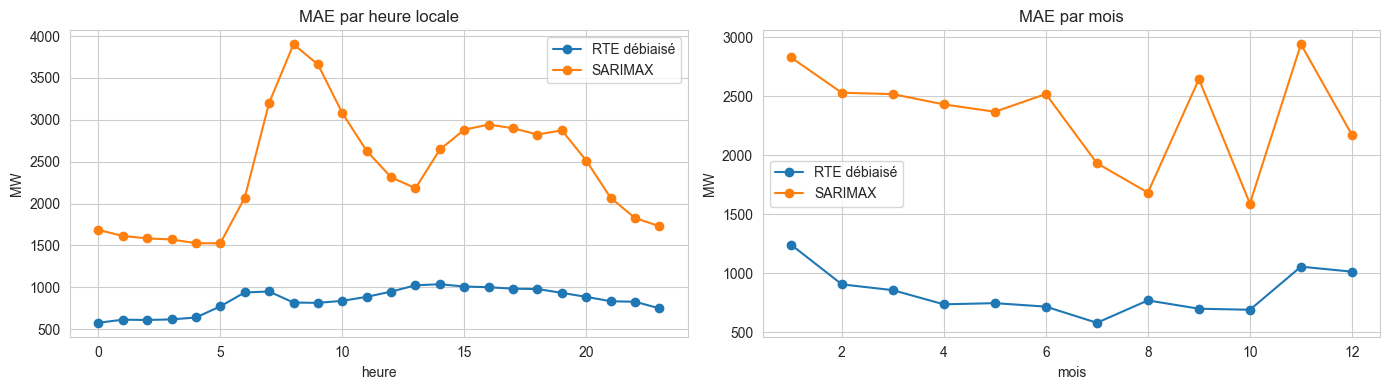

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

hour = pd.DataFrame({'RTE débiaisé': by_hour(actual, rte), 'SARIMAX': by_hour(actual, sar)})
hour.plot(ax=axes[0], marker='o', title='MAE par heure locale')
axes[0].set(xlabel='heure', ylabel='MW')

month = pd.DataFrame({'RTE débiaisé': by_month(actual, rte), 'SARIMAX': by_month(actual, sar)})
month.plot(ax=axes[1], marker='o', title='MAE par mois')
axes[1].set(xlabel='mois', ylabel='MW')
plt.tight_layout()

## 8. Conclusion

**SARIMAX perd nettement: 2407 MW de MAE contre 845 MW pour RTE débiaisé**, soit trois fois plus d'erreur (MAPE 4,8 % contre 1,7 %). Il fait mieux que la persistance à 7 jours (3675 MW) et sans biais (+20 MW), mais il ne bat même pas RTE brut (1448 MW), qui traîne pourtant +1055 MW de biais. Aucun résultat ici ne laisse penser qu'un SARIMAX mieux réglé comblerait l'écart.

**Où il échoue.**

- **Sur les pics du soir d'hiver (18-21 h, DJF)**, ceux qui coûtent le plus cher: 2674 MW contre 1174 MW pour RTE débiaisé. L'erreur est maximale vers 20 h (environ 2500 MW).
- **Toute l'année**, et pas seulement en hiver: l'erreur du modèle reste supérieure à celle de RTE tous les mois, entre 1600 MW (octobre) et 2900 MW (novembre).
- **Sur la nuit aussi** (environ 1600 MW à 2-3 h): le niveau de base est mal calé.

**Pourquoi.** À 13-36 h d'horizon, le modèle ne dispose que de la charge jusqu'à 11 h et de régresseurs calendaires/température. Pistes plausibles, non testées ici: la mémoire autorégressive s'estompe avec l'horizon, et la température n'entre que par deux termes linéaires par morceaux (HDD, CDD), identiques à toutes les heures.

**Ce que ça justifie.** Le notebook suivant passe à un modèle ML (XGBoost) qui peut apprendre des interactions heure × jour × température, et utiliser des lags sûrs (48 h et plus) que le SARIMAX ne sait pas exploiter. Le SARIMAX reste la référence « purement statistique »: 2407 MW est le niveau à dépasser avant de parler d'apport du ML, et 845 MW reste la barre à battre.

**Réserve.** Les régresseurs de température lisent la valeur à l'heure cible, ce qui suppose une prévision météo parfaite. Le SARIMAX est donc ici dans un cadre favorable et son résultat réel serait plus mauvais; la robustesse à une météo bruitée sera mesurée plus tard avec `perturb_temperature`.